# SymPhase tutorial 26 — self-consistent magnon decay

The Born (on-shell) decay rate of tutorial 24, $\Gamma_k=-2\,\mathrm{Im}\,\Sigma^{(3)}_k(\varepsilon_k)$ with bare internal magnons, is singular at
decay thresholds (the two-magnon continuum has van Hove edges) and becomes larger than the magnon energy when the coupling is strong.
`SelfConsistentDecay` treats the decay non-perturbatively on a **closed** $k$ grid (all $k$, $q$, $k-q$ on the grid):

* **iΓ approximation** (Chernyshev & Zhitomirsky, RMP 85, 219 (2013)): the internal magnons of the resonant channels carry their own
  damping, $\omega-\varepsilon_q-\varepsilon_{k-q}+i(\Gamma_q+\Gamma_{k-q})/2$, and $\Gamma_k=-2\,\mathrm{Im}\,\Sigma_k(E_k)$ is iterated to self-consistency;
* the energy stays the **$1/S$ on-shell value** $E_k=\varepsilon_k+\delta\varepsilon_{\rm HF}+\mathrm{Re}\,\Sigma^{(3)}(\varepsilon_k)+\Sigma_{\rm tad}$ — evaluating $\mathrm{Re}\,\Sigma$ off-shell would
  mix orders and destroy the Hartree–Fock/cubic Goldstone cancellation (`mode="dyson"` shows this, as a diagnostic);
* the anti-resonant (source) poles are not broadened, and the broadened resonant poles use a short-tailed (Gaussian) line shape of
  FWHM $2\eta+\Gamma_q+\Gamma_{k-q}$ (`profile="lorentz"` for the canonical Lorentzian — see §4 why it fails near Goldstone modes).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import math, numpy as np, spglib
import matplotlib.pyplot as plt
from symphase.magint import FourMagnonHF, MagnonSelfEnergy
from symphase.magcheck import BosonCluster, classical_expansion
from symphase.magnons import relax_spins, make_path, analyse
from symphase.tensors import read_poscar, read_incar
a = 3.0

def canted_chain(h=4.2):
    """AFM chain, XYZ exchange (Jy = 1.3), field h along −z: canted, gapped — the ED test bed"""
    J = np.diag([1.0, 1.3, 1.0]); S = np.array([1.0, 1.0])
    pairs = [(0, 1, np.array([a, 0, 0.]), J), (1, 0, np.array([a, 0, 0.]), J)]
    hfield = np.array([[0, 0, -h]] * 2)
    dirs, _, _ = relax_spins(np.array([[0, 1, 0.5], [0, -1, 0.5]]), S, [0, 1], pairs, [None, None], hfield=hfield,
                             steps=200000, tol=1e-15)
    return FourMagnonHF(np.diag([2 * a, 12, 12]), np.array([[0, 0, 0], [a, 0, 0.]]), [0, 1], dirs, S, pairs, None, hfield)

def triangular(S=0.5, G=36):
    """120° triangular AFM (√3×√3 cell of examples/vasp/Triangular_120AFM_INCAR), J = 1 meV"""
    d = "../examples/vasp/Triangular_120AFM_INCAR"
    p = read_poscar(f"{d}/POSCAR"); mags = np.array(read_incar(f"{d}/INCAR")["magmom"]).reshape(-1, 3)
    ds = spglib.get_symmetry_dataset((p["lattice"], p["frac"], [0, 0, 0]))
    m = analyse(p["lattice"], p["frac"], [0, 0, 0], ["Cr"] * 3, mags, ds.rotations, ds.translations, J=[1.0], spin=S,
                rmax=3.1, return_model=True)
    hf = FourMagnonHF.from_model(np.asarray(p["lattice"], float), np.asarray(p["frac"], float), m).solve(grid=(G, G, 1))
    return hf, MagnonSelfEnergy(hf)

def canted_square(hr, S=1.0):
    """square-lattice Heisenberg AFM (J = 1 meV) in a field h = hr·h_s along z (h_s = 8JS), √2 cell"""
    lat = np.array([[a, a, 0], [a, -a, 0], [0, 0, 12.]])
    pairs = [(0, 1, np.array(d, float), np.eye(3)) for d in ([a, 0, 0], [-a, 0, 0], [0, a, 0], [0, -a, 0])]
    s = math.sqrt(1 - hr ** 2)
    hf = FourMagnonHF(lat, np.array([[0, 0, 0], [a, 0, 0.]]), [0, 1], np.array([[s, 0, hr], [-s, 0, hr]]),
                      np.array([S, S]), pairs, None, np.array([[0, 0, -8 * hr * S]] * 2))
    return hf, MagnonSelfEnergy(hf), lat

def square_fm(J=-2.0, K=0.5, S=1.0):
    """square-lattice ferromagnet, easy axis z (gap 2KS)"""
    pairs = [(0, 0, np.array([a, 0, 0.]), J * np.eye(3)), (0, 0, np.array([0, a, 0.]), J * np.eye(3))]
    hf = FourMagnonHF(np.diag([a, a, 12.]), np.zeros((1, 3)), [0], np.array([[0, 0, 1.]]), np.array([S]), pairs,
                      [np.diag([0, 0, -K])], None)
    return hf, MagnonSelfEnergy(hf)

def ed_check(h=4.2, nmax=8):
    """exact diagonalisation (3-cell cluster) vs bubble + tadpole and four-magnon sunset; returns rows per mode"""
    hf = canted_chain(h); se = MagnonSelfEnergy(hf)
    cl = BosonCluster(hf, 3, nmax); qs = cl.kpoints(); k = qs[1]; e = se._mset(k)[0]
    H2 = cl.quadratic()
    ed3 = cl.second_order(H2, cl.operator(se.terms3), e)
    hf.update(qs, 0.0); ed4 = cl.second_order(H2, cl.operator(se.terms4) - cl.operator(cl.hf_terms()), e); hf.hf = None
    rows = []
    for n in range(2):
        _, w, ee = se.cubic_poles(k, n, 0.0, qs=qs); bub = float(np.sum(w / (e[n] - ee)).real)
        tad = se.tadpole(k, n, 0.0, ks=qs)
        _, w, ee = se.quartic_poles(k, n, 0.0, qs=qs); sun = float(np.sum(w / (e[n] - ee)).real)
        rows.append(dict(n=n, eps=e[n], ed3=ed3[n]["second"], bubble=bub, tadpole=tad, ed4=ed4[n]["second"], sunset=sun))
    return rows

def tri_velocity(se, hf, kf=0.03):
    """2S·δε/ε of the three Goldstone branches at small k (x direction): HF (first order), Re Σ³, total"""
    k = np.array([kf * 2 * np.pi / a, 0, 0])
    o = se.onshell(k, 0.0, (36, 36, 1), eta=0.01)
    dhf = hf.first_order_shift([k])[0]
    S2 = 2 * hf.S[0]
    return dict(e0=o["e0"], hf=S2 * dhf / o["e0"], re3=S2 * o["re3"] / o["e0"],
                total=S2 * (dhf + o["re3"] + o["tad"]) / o["e0"], gamma3=o["gamma3"])

from symphase.magint import SelfConsistentDecay

def sc_square(S=1.0, hr=0.85, G=10, eta=0.05):
    """canted square AFM in a field, self-consistent decay object on a closed G×G grid (η = eta·S)"""
    hfq, seq, latq = canted_square(hr, S=S)
    return seq, SelfConsistentDecay(seq, grid=(G, G, 1), eta=eta * S), latq

def born_vs_sc(sc):
    """(Born Γ, self-consistent Γ) on the grid (Goldstone points removed)"""
    sc.solve("onshell"); g0 = sc.G.copy()
    sc.solve("sc", mix=0.3, maxiter=300, tol=1e-6 * max(1.0, sc.e0.max() / 6.8))
    m = ~sc.gold
    return g0[m], sc.G[m].copy()


## 1. Born versus self-consistent decay (square AFM at h = 0.85 h_s, S = 1)

Born: max Γ = 2.617, mean 0.957 meV;  self-consistent: max 1.298, mean 0.557 meV
63 iterations, residual 5.5e-07 meV


Text(0.5, 1.0, 'all grid magnons')

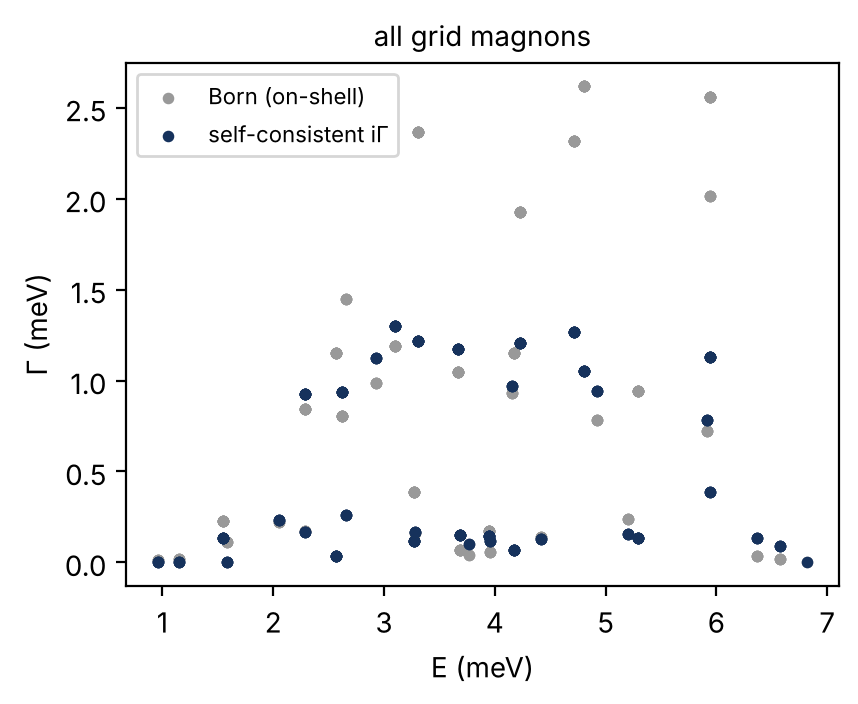

In [3]:
se1, sc1, lat1 = sc_square(1.0)
g_born, g_sc = born_vs_sc(sc1)
print(f"Born: max Γ = {g_born.max():.3f}, mean {g_born.mean():.3f} meV;  self-consistent: max {g_sc.max():.3f}, mean {g_sc.mean():.3f} meV")
print(f"{sc1.iterations} iterations, residual {sc1.residual():.1e} meV")
fig, ax = plt.subplots(figsize=(4.6, 3.4))
ax.scatter(sc1.E1S[~sc1.gold], g_born, s=10, color="0.6", label="Born (on-shell)")
ax.scatter(sc1.E1S[~sc1.gold], g_sc, s=10, color="#16325c", label="self-consistent iΓ")
ax.set_xlabel("E (meV)"); ax.set_ylabel("Γ (meV)"); ax.legend(fontsize=8); ax.set_title("all grid magnons", fontsize=10)

## 2. The Born limit for large S

Interaction effects scale as $1/S$: for $S\to\infty$ the internal widths are negligible on the scale of the continuum and the
self-consistent result must approach the Born one (η scaled with S):

In [4]:
for S in (1.0, 3.0, 10.0, 100.0):
    _, scS, _ = sc_square(S)
    gb, gs = born_vs_sc(scS)
    print(f"S = {S:5.0f}: ⟨Γ_sc⟩/⟨Γ_Born⟩ = {gs.mean() / gb.mean():.3f}   ({scS.iterations} iterations)")

S =     1: ⟨Γ_sc⟩/⟨Γ_Born⟩ = 0.582   (63 iterations)


S =     3: ⟨Γ_sc⟩/⟨Γ_Born⟩ = 0.735   (50 iterations)


S =    10: ⟨Γ_sc⟩/⟨Γ_Born⟩ = 0.838   (38 iterations)


S =   100: ⟨Γ_sc⟩/⟨Γ_Born⟩ = 1.045   (26 iterations)


## 3. Threshold singularities are removed

h/h_s = 0.72: max Γ Born 0.384   self-consistent 0.082 meV


h/h_s = 0.75: max Γ Born 1.030   self-consistent 0.130 meV


h/h_s = 0.78: max Γ Born 2.953   self-consistent 0.407 meV


h/h_s = 0.80: max Γ Born 3.278   self-consistent 0.870 meV


h/h_s = 0.85: max Γ Born 2.617   self-consistent 1.298 meV


h/h_s = 0.90: max Γ Born 2.634   self-consistent 1.740 meV


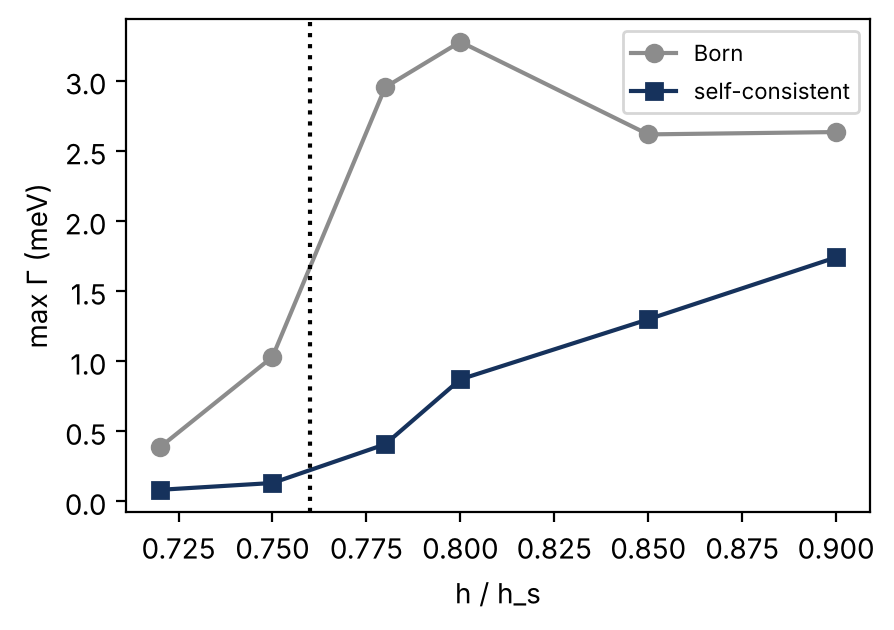

In [5]:
hrs = [0.72, 0.75, 0.78, 0.8, 0.85, 0.9]; mb, ms = [], []
for hr in hrs:
    _, scH, _ = sc_square(1.0, hr=hr); gb, gs = born_vs_sc(scH); mb.append(gb.max()); ms.append(gs.max())
    print(f"h/h_s = {hr:.2f}: max Γ Born {mb[-1]:.3f}   self-consistent {ms[-1]:.3f} meV")
fig, ax = plt.subplots(figsize=(4.8, 3.2)); ax.plot(hrs, mb, "o-", color="0.55", label="Born"); ax.plot(hrs, ms, "s-", color="#16325c", label="self-consistent")
ax.axvline(0.76, ls=":", color="k"); ax.set_xlabel("h / h_s"); ax.set_ylabel("max Γ (meV)"); ax.legend(fontsize=8)

## 4. Non-collinear magnets: Goldstone modes stay undamped

Triangular AFM, $S=\frac12$: the energies are the converged $1/S$ values (`energy_grid`); compare the line shapes of the internal widths.
The Lorentzian tails act on the very large off-resonant decay weights (the same terms that cancel the ±37ε Hartree–Fock gap) and
damp the Goldstone branches unphysically; the Gaussian keeps them underdamped:

In [6]:
hf_t, se_t = triangular(S=0.5, G=24)
for prof in ("gauss", "lorentz"):
    scT = SelfConsistentDecay(se_t, grid=(12, 12, 1), eta=0.02, energy_grid=(24, 24, 1), profile=prof)
    scT.solve("onshell"); gB = scT.G.copy()
    scT.solve("sc", mix=0.3, maxiter=300, tol=1e-6)
    sm = (~scT.gold) & (scT.E1S < 0.35)
    print(f"{prof:8s}: near-Goldstone max Γ/E = {(scT.G[sm] / scT.E1S[sm]).max():.3f} (Born {(gB[sm] / scT.E1S[sm]).max():.3f}), "
          f"⟨Γ⟩ = {scT.G[~scT.gold].mean():.3f} meV, residual {scT.residual():.1e}")

gauss   : near-Goldstone max Γ/E = 0.000 (Born 0.036), ⟨Γ⟩ = 0.010 meV, residual 6.9e-07


lorentz : near-Goldstone max Γ/E = 1.920 (Born 0.036), ⟨Γ⟩ = 0.202 meV, residual 8.6e-07


## 5. Spectral function with self-consistent internal lines

∫A dω (self-consistent): 0.982


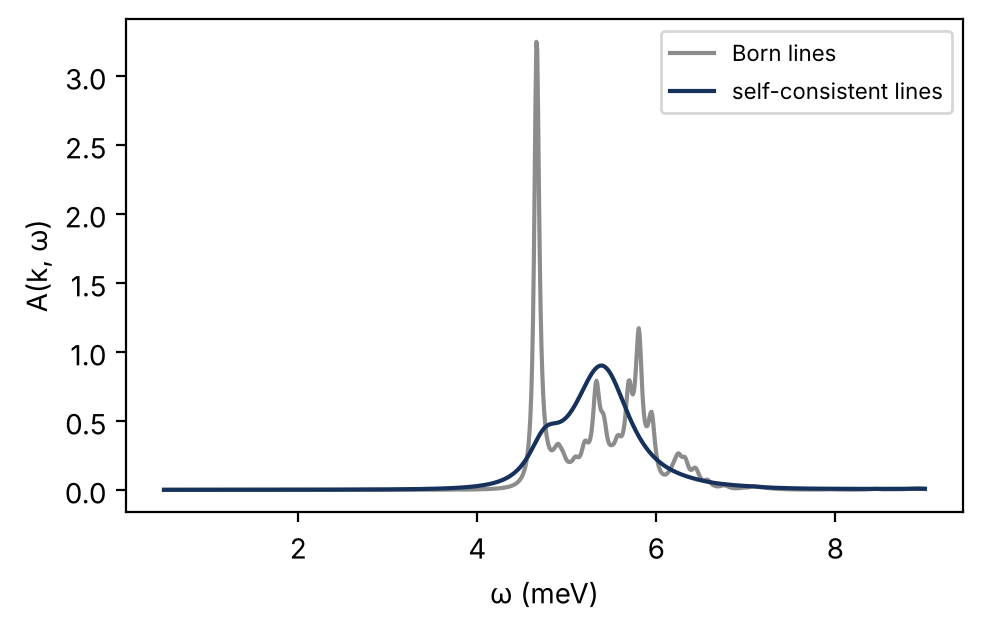

In [7]:
k5 = np.array([0.35 * 2 * np.pi / 6.0, 0.35 * 2 * np.pi / 6.0, 0])
ws = np.linspace(0.5, 9, 900)
n5 = 1
A_sc = sc1.spectral(k5, n5, ws, mode="sc"); A_b = sc1.spectral(k5, n5, ws, mode="onshell")
fig, ax = plt.subplots(figsize=(5.4, 3.2)); ax.plot(ws, A_b, color="0.55", label="Born lines"); ax.plot(ws, A_sc, color="#16325c", label="self-consistent lines")
ax.set_xlabel("ω (meV)"); ax.set_ylabel("A(k, ω)"); ax.legend(fontsize=8)
print("∫A dω (self-consistent):", round(np.trapezoid(A_sc, ws), 3))

## Command line
```bash
cd examples/vasp/Triangular_120AFM_INCAR
symphase magnons --J 1 --spin 0.5 --rmax 3.1 --hf 0 --hf-grid 30 30 --cubic --sc-decay --sc-grid 12 12 --se-sigma 0.03 --nq 16 --se-every 2
```
Writes `*_scdecay.dat` (ε, E, Γ_sc, Z) and adds the self-consistent band and widths to `*_hf.png`.
Limits: the energies are the 1/S on-shell values; cubic self-energy only (Γ⁴ is added on top); grid convergence of Γ should be checked
(closed grids are coarse). Continue with **27_quiz_self_consistent_decay.ipynb**.